# 04 Entity Extraction

In [ ]:
import re
import spacy
import pandas as pd
import numpy as np
from collections import Counter

In [4]:
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 21.6 MB/s  0:00:00eta 0:00:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


### Load both datasets

In [57]:
doc_topics = pd.read_parquet("doc_topics.parquet")
clean_df = pd.read_parquet("clean_news_final_project.parquet")

print("doc_topics:", doc_topics.shape)
print("clean_df:", clean_df.shape)

doc_topics: (115006, 8)
clean_df: (115006, 10)


### Reconstruct article_text

In [58]:
clean_df["article_text"] = (
    clean_df["title"].fillna("").astype(str) + ". " +
    clean_df["text_clean"].fillna("").astype(str)
)

### Merge datasets

In [59]:
df = doc_topics.merge(
    clean_df[["date", "domain", "title", "article_text"]],
    on=["date", "domain", "title"],
    how="left"
)

print(df.shape)
df.head()

(116358, 9)


,date,domain,title,topic_id,topic_label,industry,topic_keep,macro_topic,article_text
0,2024-07-01,boingboing.net,This AI video of gymnastics might be the freak...,6,Generative AI Applications,Software / AI Platforms,1,AI Applications,This AI video of gymnastics might be the freak...
1,2024-09-22,boingboing.net,"If using AI feels like a chore, try this - Boi...",6,Generative AI Applications,Software / AI Platforms,1,AI Applications,"If using AI feels like a chore, try this - Boi..."
2,2024-03-13,clickup.com,Best AI Prompts for Business Risk Management,10,Enterprise AI Applications,Enterprise Software,1,AI Applications,Best AI Prompts for Business Risk Management. ...
3,2025-12-15,crooksandliars.com,State AGs Warn AI Companies: Clean Up Your Chi...,9,AI Policy and Geopolitics,Government / Public Policy,1,AI Policy,State AGs Warn AI Companies: Clean Up Your Chi...
4,2023-07-26,dbtnews.com,Bullfrog AI Holdings Inc. [BFRG] Revenue clock...,1,AI Chips and Semiconductor Industry,Semiconductors,1,AI Hardware,Bullfrog AI Holdings Inc. [BFRG] Revenue clock...


### Check missing text

In [60]:
print("Missing article_text:", df["article_text"].isna().sum())

Missing article_text: 0


## Organization Extraction

Organizations are extracted using spaCy's Named Entity Recognition (NER) model.
The model identifies entities labeled as `ORG`.

After extraction, the entities are cleaned using:

- a blacklist to remove generic terms
- filtering of short tokens
- removal of non-English tokens

This ensures that only valid organization names remain.

### Sample test for ORG extraction

In [61]:
sample_texts = df["article_text"].sample(5, random_state=42)

for text in sample_texts:
    
    doc = nlp(text[:2000])
    
    orgs = [ent.text for ent in doc.ents if ent.label_ == "ORG"]
    
    print(orgs)

['Google', 'Bard’s AI', 'Bard’s AI', 'Bard’s AI', 'TSMC', 'Intel', 'USB stickBy Roshan ShaikhNovember 22', '2023Intel', 'Meteor Lake', 'GPU', 'AMD', 'Radeon 780M', 'XTX', 'Anton']
['the World of Artificial Intelligence', 'the World of Artificial Intelligence', 'Altman', 'Altman']
['Latest Local & Regional Stories\nFederal', "Wynnewood Refinery's", 'The University of Tulsa']
['Reduction and Efficiency Improvement', 'IBM', 'Microsoft', 'Google', 'Google', 'AI']
['MEXC News', 'ICO', 'Meme', 'Proof of Liquidity', 'Berachain', 'AI', 'Beras Capital', 'NFT', 'DAO', 'Swarm Technology', 'ETH', 'NFT', 'Byle Davies']


In [ ]:
nlp = spacy.load("en_core_web_sm")

org_normalization_map = {
    # Big tech
    "google": "Google",
    "alphabet": "Google",
    "alphabet inc": "Google",
    "google llc": "Google",
    "google deepmind": "Google DeepMind",
    "deepmind": "Google DeepMind",

    "microsoft": "Microsoft",
    "msft": "Microsoft",
    "microsoft corp": "Microsoft",
    "microsoft corporation": "Microsoft",

    "openai": "OpenAI",

    "meta": "Meta",
    "facebook": "Meta",
    "meta platforms": "Meta",

    "amazon": "Amazon",
    "amazon web services": "Amazon",
    "aws": "Amazon",

    "apple": "Apple",
    "nvidia": "NVIDIA",
    "amd": "AMD",
    "intel": "Intel",
    "qualcomm": "Qualcomm",
    "tsmc": "TSMC",
    "taiwan semiconductor": "TSMC",
    "samsung": "Samsung",
    "oracle": "Oracle",
    "ibm": "IBM",
    "adobe": "Adobe",
    "salesforce": "Salesforce",
    "sap": "SAP",
    "servicenow": "ServiceNow",
    "snowflake": "Snowflake",
    "palantir": "Palantir",

    # AI companies
    "anthropic": "Anthropic",
    "hugging face": "Hugging Face",
    "huggingface": "Hugging Face",
    "stability ai": "Stability AI",
    "midjourney": "Midjourney",
    "perplexity": "Perplexity",
    "cohere": "Cohere",
    "character ai": "Character.AI",
    "mistral": "Mistral AI",
    "mistral ai": "Mistral AI",
    "inflection": "Inflection AI",
    "inflection ai": "Inflection AI",

    # China / Asia
    "baidu": "Baidu",
    "alibaba": "Alibaba",
    "tencent": "Tencent",
    "bytedance": "ByteDance",
    "huawei": "Huawei",
    "xiaomi": "Xiaomi",

    # Chips / hardware / gaming / others
    "arm": "ARM",
    "broadcom": "Broadcom",
    "asml": "ASML",
    "micron": "Micron",
    "ubisoft": "Ubisoft",
    "unity": "Unity",
    "hasbro": "Hasbro",
    "canva": "Canva",
    "cloudastructure": "Cloudastructure",
    "clickup": "ClickUp",
    "lenovo": "Lenovo",
    "costco": "Costco",
    "blackrock": "BlackRock",
    "vanguard": "Vanguard",
    "reuters": "Reuters",
    "bloomberg": "Bloomberg",
}

In [62]:
bad_org_terms = {
    "ai", "artificial intelligence", "technology", "business", "data", "market",
    "news", "story", "network", "article", "media", "company", "service",
    "help", "bad", "complete", "today", "world", "group", "team", "system",
    "platform", "software", "seo", "church", "magic", "discover", "united",
    "image", "images", "foundation", "foundations", "modem", "silicon",
    "semiconductor", "oscars", "hollywood", "school", "student", "students",
    "chatgpt", "claude", "gemini", "copilot", "windows", "ipad", "iphones",
    "iphone", "android"
}

news_source_noise = {
    "reuters", "bloomberg", "fedtech magazine", "gamesradar", "hollywood exbulletin"
}

In [63]:
def looks_like_company(x):

    if not x or not isinstance(x,str):
        return False

    x = x.lower().strip()

    if len(x) <= 2:
        return False

    bad_terms = {
        "ai","technology","news","business","article",
        "data","market","story","network","system",
        "platform","software","image","modem"
    }

    if x in bad_terms:
        return False


    company_suffix = (
        "inc","corp","corporation","llc","ltd","limited",
        "technologies","technology","systems","group","holdings"
    )

    if any(x.endswith(" "+s) for s in company_suffix):
        return True


    if x in org_normalization_map:
        return True

    if len(x.split()) == 1 and len(x) > 3:
        return True

    return False

In [64]:
def normalize_org(org):

    if not isinstance(org,str):
        return None

    x = org.lower().strip()

    x = re.sub(r"[^\w\s]", "", x)
    x = re.sub(r"\d+","",x)
    x = re.sub(r"\s+"," ",x)

    tokens = x.split()

    if len(tokens)==0:
        return None

    first = tokens[0]

    if first in org_normalization_map:
        return org_normalization_map[first]

    if x in org_normalization_map:
        return org_normalization_map[x]

    if not looks_like_company(x):
        return None

    return first.title()

In [70]:
def extract_orgs_batch(texts):

    results = []

    for doc in nlp.pipe(
        texts,
        batch_size=100,
        disable=["parser","tagger","lemmatizer"]
    ):

        orgs = []

        for ent in doc.ents:
            if ent.label_ == "ORG":
                norm = normalize_org(ent.text)
                if norm:
                    orgs.append(norm)

        results.append(list(set(orgs)))

    return results

In [71]:
df["org_list"] = extract_orgs_batch(df["article_text"])

df[["title", "org_list"]].head()

,title,org_list
0,This AI video of gymnastics might be the freak...,"[Apple, Yanartas, Microsoft]"
1,"If using AI feels like a chore, try this - Boi...","[Claude, Frenchie, Diskprices, Lenovo, Ebay, S..."
2,Best AI Prompts for Business Risk Management,[ClickUp]
3,State AGs Warn AI Companies: Clean Up Your Chi...,"[Microsoft, Costco, OpenAI, Crooks, Amazon, Re..."
4,Bullfrog AI Holdings Inc. [BFRG] Revenue clock...,"[Microvast, Nasdaq, Vanguard, BlackRock, Bullf..."


In [72]:
df.to_parquet("doc_entities_stage_d_working.parquet", index=False)

In [129]:
df["org_list"].explode().value_counts().head(30)

org_list
Google        16407
Microsoft     16215
OpenAI        12716
Amazon         8104
Apple          7437
Meta           5487
NVIDIA         3499
Samsung        3195
Menafn         3074
Intel          2755
IBM            2160
Tiktok         2096
AMD            1869
Youtube        1378
Tesla          1374
Newscrypto     1363
Cnbc           1237
Altman         1224
Huawei         1079
Fiat           1041
Sony           1033
Union           982
Nasa            967
Alexa           964
Oracle          950
Mexc            950
Adobe           924
State           915
Recognise       879
Parliament      845
Name: count, dtype: int64

After we reviewed the output, there still left some noisy. Thus, we create a balcklist for light filter.

In [130]:
org_blacklist = {
"Healthcare","Company","Companies","Digital","Technology",
"News","Business","Market","Data","The","House","Tech",
"Congress","Senate","Nasdaq","Nyse","Reuters","Iphones",
"Prnewswire","Android","Iphone","Javascript","Covid","Future",
"Ethereum","Usdc","Usdt","Gemini","Claude","Chatgpt","Copilot",
"A","AI","Platform","Startup","Startups"
}

In [131]:
import re

def clean_orgs(orgs):
    if not isinstance(orgs, list):
        return []
    
    clean = []
    
    for o in orgs:
        
        if o in org_blacklist:
            continue
            
        if len(o) <= 2:
            continue
            
        if not re.match("^[A-Za-z0-9 .&-]+$", o):
            continue
            
        clean.append(o)
        
    return clean

In [144]:
df["org_list"] = df["org_list"].apply(clean_orgs)
df["org_list"].explode().value_counts().head(30)

org_list
Google        16407
Microsoft     16215
OpenAI        12716
Amazon         8104
Apple          7437
Meta           5487
NVIDIA         3499
Samsung        3195
Menafn         3074
Intel          2755
IBM            2160
Tiktok         2096
AMD            1869
Youtube        1378
Tesla          1374
Newscrypto     1363
Cnbc           1237
Altman         1224
Huawei         1079
Fiat           1041
Sony           1033
Union           982
Nasa            967
Alexa           964
Oracle          950
Mexc            950
Adobe           924
State           915
Recognise       879
Parliament      845
Name: count, dtype: int64

### Tech taxonomy

#### Technology Extraction

In addition to organizations, the project also extracts AI-related technology and adoption mechanism terms from the news corpus.

Because these technology mentions are often not standard named entities, a taxonomy-based keyword matching approach is used instead of NER.

In [145]:
tech_taxonomy = {
    "Automation": [
        "automation", "automate", "automated", "rpa",
        "process automation", "robotic process automation"
    ],
    "Augmentation": [
        "copilot", "co-pilot", "assistant", "ai assistant",
        "augmentation", "augment"
    ],
    "Workflow Redesign": [
        "workflow", "workflow redesign", "orchestration",
        "agentic workflow", "agentic", "agent", "agents", "multi-agent"
    ],
    "Cost Reduction / Efficiency": [
        "cost reduction", "reduce cost", "efficiency",
        "productivity", "optimize", "optimization", "save time"
    ],
    "Robotics / Physical Automation": [
        "robot", "robots", "robotic", "robotics",
        "physical automation", "industrial robot",
        "autonomous vehicle", "self-driving", "drone"
    ],
    "Governance / Compliance": [
        "governance", "compliance", "audit", "auditing",
        "monitoring", "risk management", "ai safety", "alignment"
    ],
    "Generative AI / LLM": [
        "generative ai", "llm", "large language model",
        "foundation model", "gpt", "chatgpt", "gemini",
        "claude", "diffusion", "transformer"
    ],
    "AI Infrastructure / Chips": [
        "infrastructure", "chips", "semiconductor",
        "hardware", "gpu", "tpu", "asic", "fpga"
    ],
    "AI Services / Cloud": [
        "cloud", "ai service", "api", "platform",
        "as a service", "saas"
    ],
    "AI Research / Development": [
        "research", "development", "r&d",
        "innovation", "discovery"
    ],
    "Data / Model Training": [
    "training data","dataset","datasets",
    "fine-tuning","fine tuning",
    "model training","pretraining","data pipeline"
    ]
}

### Extraction function

In [146]:
def extract_tech_list(text):
    if not isinstance(text, str):
        return []

    x = text.lower()
    found = []

    for category, keywords in tech_taxonomy.items():
        for kw in keywords:
            if kw in x:
                found.append(category)
                break

    return found

In [147]:
df["tech_list"] = df["article_text"].apply(extract_tech_list)

### Technology frequency

In [148]:
df[["title", "tech_list"]].head(20)

,title,tech_list
0,This AI video of gymnastics might be the freak...,[]
1,"If using AI feels like a chore, try this - Boi...","[Generative AI / LLM, AI Infrastructure / Chip..."
2,Best AI Prompts for Business Risk Management,"[Cost Reduction / Efficiency, Governance / Com..."
3,State AGs Warn AI Companies: Clean Up Your Chi...,[AI Infrastructure / Chips]
4,Bullfrog AI Holdings Inc. [BFRG] Revenue clock...,[]
5,Qualcomm announces new AI chips in data center...,"[Cost Reduction / Efficiency, Governance / Com..."
6,IIM Ahmedabad student writes project using Cha...,"[Generative AI / LLM, AI Services / Cloud, AI ..."
7,chatgpt: Can a chatbot preach a good sermon? H...,[Generative AI / LLM]
8,OpenAI goes in search of more suckers in Holly...,[]
9,4 Principles to Help Federal Agencies Adopt AI...,"[Workflow Redesign, Governance / Compliance, A..."


In [158]:
df["tech_list"].explode().value_counts()

tech_list
AI Services / Cloud               60686
Generative AI / LLM               46699
AI Research / Development         45286
AI Infrastructure / Chips         32073
Cost Reduction / Efficiency       22333
Automation                        19356
Governance / Compliance           18856
Workflow Redesign                 15428
Augmentation                      14570
Robotics / Physical Automation    11599
Data / Model Training              6814
Name: count, dtype: int64

### Entity Dataset

In [159]:
doc_entities = df[
    ["date","domain","title","topic_id","topic_label",
     "industry","macro_topic","org_list","tech_list"]
].copy()

doc_entities.to_parquet("doc_entities.parquet")

### Organization distionary

In [160]:
org_dict = (
    df["org_list"]
    .explode()
    .dropna()
    .value_counts()
    .reset_index()
)

org_dict.columns = ["organization","count"]

org_dict.to_csv("org_dict.csv", index=False)

### Technology dictionary

In [161]:
tech_dict = (
    df["tech_list"]
    .explode()
    .dropna()
    .value_counts()
    .reset_index()
)

tech_dict.columns = ["technology","count"]

tech_dict.to_csv("tech_dict.csv", index=False)

## Technology Patterns

### Industry × Technology

<Axes: xlabel='tech_list'>

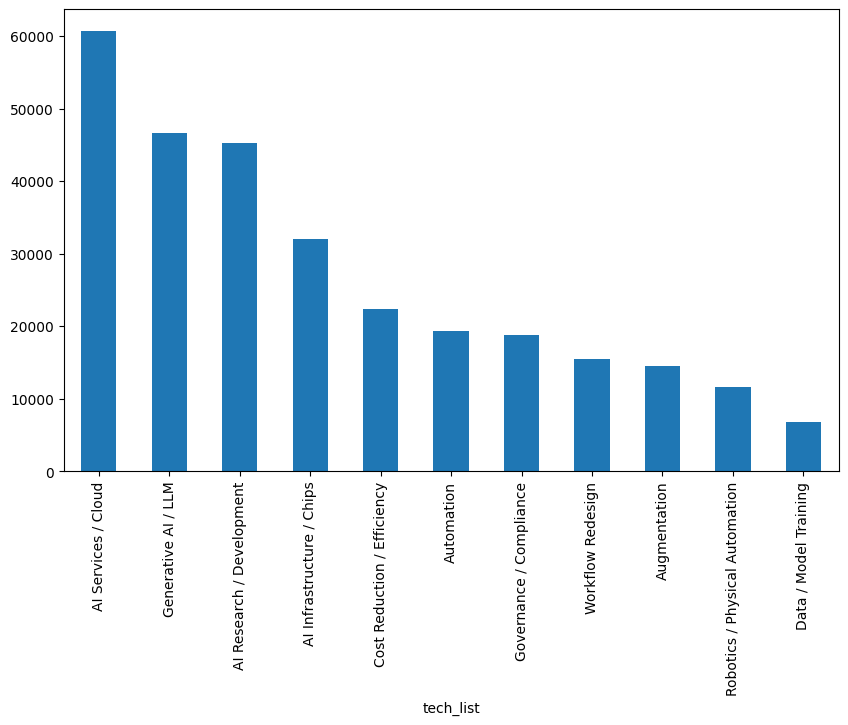

In [162]:
tech_freq = df["tech_list"].explode().value_counts()

tech_freq.plot(kind="bar", figsize=(10,6))

### Heatmap

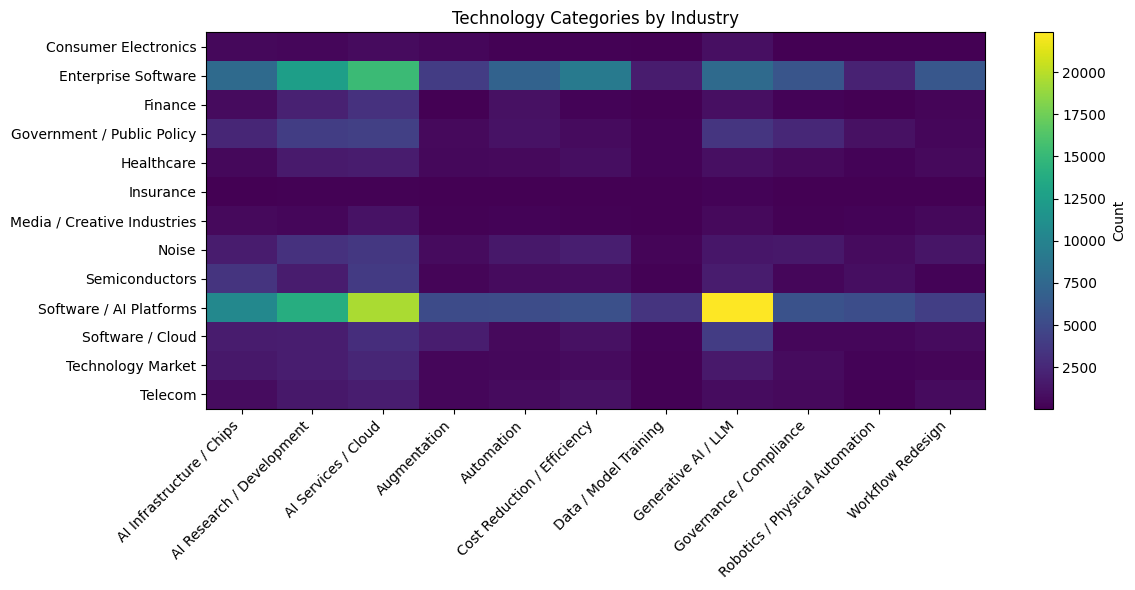

In [154]:
import pandas as pd
import matplotlib.pyplot as plt

tech_industry_pivot = tech_industry.pivot(
    index="industry",
    columns="tech_list",
    values="count"
).fillna(0)

plt.figure(figsize=(12, 6))
plt.imshow(tech_industry_pivot, aspect="auto")
plt.colorbar(label="Count")

plt.xticks(range(len(tech_industry_pivot.columns)),
           tech_industry_pivot.columns,
           rotation=45, ha="right")
plt.yticks(range(len(tech_industry_pivot.index)),
           tech_industry_pivot.index)

plt.title("Technology Categories by Industry")
plt.tight_layout()
plt.show()

### Company × Technology

In [156]:
df_ex = df.explode("org_list").explode("tech_list")

company_tech = (
    df_ex.groupby(["org_list","tech_list"])
    .size()
    .reset_index(name="count")
)

company_tech

,org_list,tech_list,count
0,AMD,AI Infrastructure / Chips,1520
1,AMD,AI Research / Development,780
2,AMD,AI Services / Cloud,1179
3,AMD,Augmentation,307
4,AMD,Automation,277
...,...,...,...
310917,Zyxel,Automation,1
310918,Zyxel,Generative AI / LLM,1
310919,Zyxel,Governance / Compliance,1
310920,Zyxi,AI Services / Cloud,1


### Top company-tech pairs

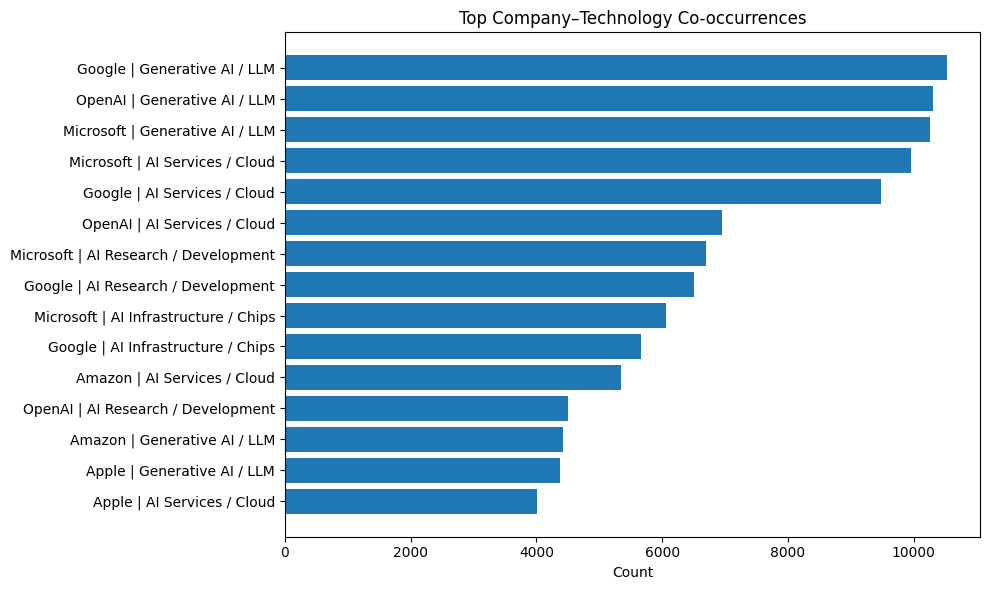

In [157]:
top_company_tech = company_tech.sort_values("count", ascending=False).head(15).copy()
top_company_tech["pair"] = top_company_tech["org_list"] + " | " + top_company_tech["tech_list"]

plt.figure(figsize=(10, 6))
plt.barh(top_company_tech["pair"], top_company_tech["count"])
plt.gca().invert_yaxis()

plt.xlabel("Count")
plt.title("Top Company–Technology Co-occurrences")
plt.tight_layout()
plt.show()